In [1]:
from typing import List, Literal,TypedDict
from pydantic import BaseModel,Field
from pypdf import PdfReader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq
from langchain_google_genai  import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings 
from langchain_community.tools.tavily_search import TavilySearchResults

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15332\1824443630.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [2]:
load_dotenv()

True

In [3]:
#---------------LOAD DOCS-----------------------------------
#Helper function to replicate PyPDFLoader
def load_pdf_as_documents(file_path: str) -> list[Document]:
    try:
        reader = PdfReader(file_path)
        documents = []

        for i, page in enumerate(reader.pages):
            text = page.extract_text() or ""
            # Replicates LangChain's default metadata schema for loaders
            metadata = {"source": file_path, "page": i}
            documents.append(Document(page_content=text, metadata=metadata))

        return documents
    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return []


# Combining docs identically
docs = (
    load_pdf_as_documents("./documents/book1.pdf")
    #+ load_pdf_as_documents("./documents/book2.pdf")
    #+ load_pdf_as_documents("./documents/book3.pdf")   
)

In [4]:
len(docs)

758

In [5]:
#-----------------------------------CHUNKING--------------------------------
#chunking the documents using Recursive Character text splitter
chunks = RecursiveCharacterTextSplitter(chunk_size =900, chunk_overlap =100).split_documents(docs)

#---------------------------Clean text to avoid UnicodeEncodeError-------------------

for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [6]:
len(chunks)

2421

In [7]:
#-----------------------Indexing------------------------------ 
#(fresh collection each run)
#------------------------------EMBED DOCS-----------------------------------
#Generating Embeddings for given docs using text-embedding-004 from google generative ai embeddings

embeddings = GoogleGenerativeAIEmbeddings(
    model = "gemini-embedding-001",# or 'models/gemini-embedding-exp-03-07'
    task_type="retrieval_document"# Options: retrieval_query, retrieval_document, semantic_similarity, etc.
)


In [8]:
#----------------------------------VECTOR STORE-----------------------------------
#Storing in vector database using  FAISS db

import time
# NEW SETTINGS: Process 100 chunks at once, then pause for 60 seconds.
# This pushes exactly 100 chunks to the API per minute, staying perfectly under the limit.
BATCH_SIZE = 100 
SLEEP_TIME_SECONDS = 60 
vector_store = None

print(f"Starting vector database creation for {len(chunks)} text chunks...")

for i in range(0, len(chunks), BATCH_SIZE):
    batch = chunks[i : i + BATCH_SIZE]
    
    if vector_store is None:
        # Create the initial vector database using the first chunk batch
        vector_store = FAISS.from_documents(batch, embeddings)
    else:
        # Add subsequent chunks to the active store instance
        vector_store.add_documents(batch)
        
    current_chunk_count = min(i + BATCH_SIZE, len(chunks))
    print(f"Embedded [{current_chunk_count}/{len(chunks)}] chunks.")
    
    # Only pause if there are still more chunks left to process
    if current_chunk_count < len(chunks):
        print(f"Pausing for {SLEEP_TIME_SECONDS} seconds to completely reset the 100 RPM quota...")
        time.sleep(SLEEP_TIME_SECONDS)

print("\n Success! All text chunks embedded and vector store created.")

Starting vector database creation for 2421 text chunks...
Embedded [100/2421] chunks.
Pausing for 60 seconds to completely reset the 100 RPM quota...
Embedded [200/2421] chunks.
Pausing for 60 seconds to completely reset the 100 RPM quota...
Embedded [300/2421] chunks.
Pausing for 60 seconds to completely reset the 100 RPM quota...


GoogleGenerativeAIError: Error embedding content (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/embed_content_free_tier_requests, limit: 1000, model: gemini-embedding-1.0\nPlease retry in 44.503824122s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/embed_content_free_tier_requests', 'quotaId': 'EmbedContentRequestsPerDayPerUserPerProjectPerModel-FreeTier', 'q

In [9]:
#-------------------------RETRIEVER-----------------------------
#Creating a retriever using vector store
retriever =  vector_store.as_retriever(search_type='similarity',search_kwargs ={"k":4})

In [10]:
#---------------------------LLM-------------------------------
llm = ChatGroq(model="llama-3.3-70b-versatile", temperature=0.2)
#llm = ChatGoogleGenerativeAI(model = "gemini-2.5-flash",temperature = 0)

In [11]:
#-------------------- Graph State ---------------------------------------
class State(TypedDict):
    question: str
    docs: List[Document]
    answer: str

In [12]:
#------------------------------NODES DEFINITION---------------------------------------
def retrieve(state):
    query = state["question"]
    return {"docs": retriever.invoke(query)}

In [13]:
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)
def generate(state):
    context = "\n\n".join(d.page_content for d in state["docs"])
    out = (prompt | llm).invoke({"question": state["question"], "context": context})
    return {"answer": out.content}

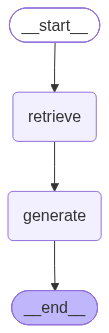

In [14]:
#---------------------------------BUILDING GRAPH-------------------------------------
graph = StateGraph(State)
graph.add_node("retrieve", retrieve)
graph.add_node("generate", generate)

graph.add_edge(START, "retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)

app = graph.compile()

app

In [ ]:
#-------------------------------------Run-----------------------------------------

result = app.invoke({"question": "WHat is a transformer in deep learning.", "docs": [], "answer": ""})
print(result["answer"])

In [ ]:
print(result['docs'][0].page_content)
print('*'*100)
print(result['docs'][1].page_content)
print('*'*100)
print(result['docs'][2].page_content)
print('*'*100)
print(result['docs'][3].page_content)